<a href="https://colab.research.google.com/github/Umair505/bangla-cyberbullying-severity-target/blob/main/Bangla_Cyberbullying_Severity_Target_v5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bangla Cyberbullying — Severity and Target Classification
This notebook builds and compares models that read one Bangla comment and predict two things: how severe the
bullying is, and who it is aimed at.

Dataset: `bangla_cyberbullying_dataset.csv` (5,858 unique comments).
Columns: `text` (cleaned comment), `Description` (original comment), `Original_Label` (content type of the
original Kaggle dataset), `Final_Severity` and `Final_Target` (our two labels).

| Severity | | Target | |
|---|---|---|---|
| 0 | Neutral | 0 | No Target |
| 1 | Mild | 1 | Individual |
| 2 | Moderate | 2 | Group |
| 3 | Severe | 3 | Community |

Run on GPU: `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.

Required files in the session: `bangla_cyberbullying_dataset.csv` and `split_frozen_v5.csv`.


## 1. Setup
Install the extra libraries and check that a GPU is available.

In [ ]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'transformers>=4.40', 'accelerate', 'shap', 'lime', 'openpyxl'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'git+https://github.com/csebuetnlp/normalizer'], check=False)
import torch
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')

torch 2.14.1+cu130 | CUDA: True | Tesla T4


## 2. Configuration
All settings are kept in one place so that nothing has to be changed later in the notebook.

In [ ]:
import os, json, random, time, re, math, hashlib, warnings
import importlib.metadata as md
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

DATA_FILE   = 'bangla_cyberbullying_dataset.csv'
SPLIT_FILE  = 'split_frozen_v5.csv'   # fixed train/val/test split; the notebook stops if it is missing
EXPECTED_SPLIT_ID = '0721b362d1'      # set to None to accept any split file
SEED        = 42
MAX_LEN     = 128
BATCH_SIZE  = 16
EPOCHS      = 6
PATIENCE    = 2
WARMUP      = 0.1
WEIGHT_DECAY= 0.01
LOSS_W      = {'sev': 1.0, 'tgt': 1.0}
USE_CLASS_WEIGHTS = True

NEAR_DUP_SIM = 0.90              # texts above this cosine stay in the same split

MODELS = {
    'BanglaBERT': ('csebuetnlp/banglabert', 2e-5),
    'XLM-R':      ('xlm-roberta-base', 2e-5),
    'mBERT':      ('bert-base-multilingual-cased', 2e-5),
}
XAI_MODEL      = 'BanglaBERT'
XAI_N_EXAMPLES = 150
SHAP_MIN_COUNT = 3

SEV_NAMES = ['Neutral', 'Mild', 'Moderate', 'Severe']
TGT_NAMES = ['No Target', 'Individual', 'Group', 'Community']

BASE = '.'
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE = '/content/drive/MyDrive/bangla_cyberbullying_thesis'
    except Exception as e:
        print('Drive not mounted, using local folder:', e)
        BASE = '/content/bangla_cyberbullying_thesis'
RES  = os.path.join(BASE, 'results_v5');     os.makedirs(RES, exist_ok=True)
PRED = os.path.join(BASE, 'predictions_v5'); os.makedirs(PRED, exist_ok=True)
CKPT = '/content/ckpt' if os.path.isdir('/content') else os.path.join(BASE, 'ckpt'); os.makedirs(CKPT, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# package versions are stored with the results, because transformer scores move between library versions
def pkg_version(name):
    try: return md.version(name)
    except Exception: return 'not installed'
VERSIONS = {p: pkg_version(p) for p in ['torch', 'transformers', 'scikit-learn', 'shap', 'lime', 'numpy', 'pandas']}

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
print('Results ->', RES)
print('Versions:', VERSIONS)


Mounted at /content/drive
Results -> /content/drive/MyDrive/bangla_cyberbullying_thesis/results_v5
Versions: {'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'scikit-learn': '1.6.1', 'shap': '0.54.1', 'lime': '0.2.0.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


## 3. Data Loading and Initial Exploration
Load the dataset and take a quick look at its shape, columns, missing values and label counts.

In [ ]:
def find_file(fname):
    for p in [fname, os.path.join(BASE, fname), os.path.join('/content', fname)]:
        if os.path.exists(p): return p
    return None

if find_file(DATA_FILE) is None and IN_COLAB:
    from google.colab import files
    print('Upload bangla_cyberbullying_dataset.csv (and split_v3.csv if you have it)')
    files.upload()

df = pd.read_csv(find_file(DATA_FILE), encoding='utf-8-sig')
df['text'] = df['text'].astype(str).str.strip()
df['sev'] = df['Final_Severity'].astype(int)
df['tgt'] = df['Final_Target'].astype(int)
df['id']  = np.arange(len(df))

assert df['text'].notna().all() and (df['text'].str.len() > 0).all(), 'empty text'
assert set(df.sev) <= {0, 1, 2, 3} and set(df.tgt) <= {0, 1, 2, 3}, 'invalid label'
print(df.shape, list(df.columns))
display(df.head(3))

Upload bangla_cyberbullying_dataset.csv (and split_v3.csv if you have it)


Saving bangla_cyberbullying_dataset.csv to bangla_cyberbullying_dataset.csv
Saving split_frozen_v5.csv to split_frozen_v5.csv
(5858, 8) ['text', 'Description', 'Original_Label', 'Final_Severity', 'Final_Target', 'sev', 'tgt', 'id']


,text,Description,Original_Label,Final_Severity,Final_Target,sev,tgt,id
0,ওই হালার পুত এখন কি মদ খাওয়ার সময় রাতের বেলা...,ওই হালার পুত এখন কি মদ খাওয়ার সময় রাতের বেলা...,sexual,3,1,3,1,0
1,আপনার জন্ম প্রক্রিয়ার সময় আপনার মায়ের ভিতর ...,আপনার জন্ম প্রক্রিয়ার সময় আপনার মায়ের ভিতর কি ...,sexual,2,1,2,1,1
2,ধজভংগ দের আর ভায়াগ্রা লাগবো না। ধংস হোক এই সব...,ধজভংগ দের আর ভায়াগ্রা লাগবো না। ধংস হোক এই সব ...,sexual,2,1,2,1,2


In [ ]:
print('shape:', df.shape)
display(df.sample(5, random_state=SEED))
df.info()

shape: (5858, 8)


,text,Description,Original_Label,Final_Severity,Final_Target,sev,tgt,id
5217,কোয়ান্টম মেথড এর সঠিকতা সম্পর্কে কিছু বলবেন।,কোয়ান্টম মেথড এর সঠিকতা সম্পর্কে কিছু বলবেন।,Neutral,0,0,0,0,5217
3671,"আপু এইরকম ছবি দিয়েন না, দিলে জখম লাগে","আপু এইরকম ছবি দিয়েন না, দিলে জখম লাগে",troll,0,0,0,0,3671
1505,আহা হা হা গুরু মেরে জুতা দান,আহা হা হা গুরু মেরে জুতা দান,Threat,0,0,0,0,1505
23,"নূর হোসেন। চুদা ত নবী হইতে শিখছো, দাসী চুুদছে,...","নূর হোসেন। চুদা ত নবী হইতে শিখছো, দাসী চুুদছে,...",sexual,2,3,2,3,23
4041,তুকে কাছে পাইলে কুত্তা দিয়ে......বাকিটা বুঝে নে।,তুকে কাছে পাইলে কুত্তা দিয়ে......বাকিটা বুঝে নে।,troll,2,1,2,1,4041


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5858 entries, 0 to 5857
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   text            5858 non-null   object
 1   Description     5858 non-null   object
 2   Original_Label  5858 non-null   object
 3   Final_Severity  5858 non-null   int64 
 4   Final_Target    5858 non-null   int64 
 5   sev             5858 non-null   int64 
 6   tgt             5858 non-null   int64 
 7   id              5858 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 366.3+ KB


In [ ]:
print('missing values\n', df.isnull().sum())
print('\nexact duplicate texts:', df.text.duplicated().sum())
print('\nOriginal_Label counts\n', df.Original_Label.value_counts())
print('\nSeverity counts\n', df.sev.value_counts().sort_index().rename(dict(enumerate(SEV_NAMES))))
print('\nTarget counts\n', df.tgt.value_counts().sort_index().rename(dict(enumerate(TGT_NAMES))))

missing values
 text              0
Description       0
Original_Label    0
Final_Severity    0
Final_Target      0
sev               0
tgt               0
id                0
dtype: int64

exact duplicate texts: 0

Original_Label counts
 Original_Label
Neutral      1200
troll        1197
sexual       1194
Threat       1191
Political    1076
Name: count, dtype: int64

Severity counts
 sev
Neutral     3211
Mild         937
Moderate    1470
Severe       240
Name: count, dtype: int64

Target counts
 tgt
No Target     3211
Individual    2162
Group          295
Community      190
Name: count, dtype: int64


## 4. Exploratory Data Analysis
Label distribution, the Severity x Target table and the comment length distribution.
In this dataset every Neutral comment has No Target, and every bullying comment has a target.

Bangla font: Mukti


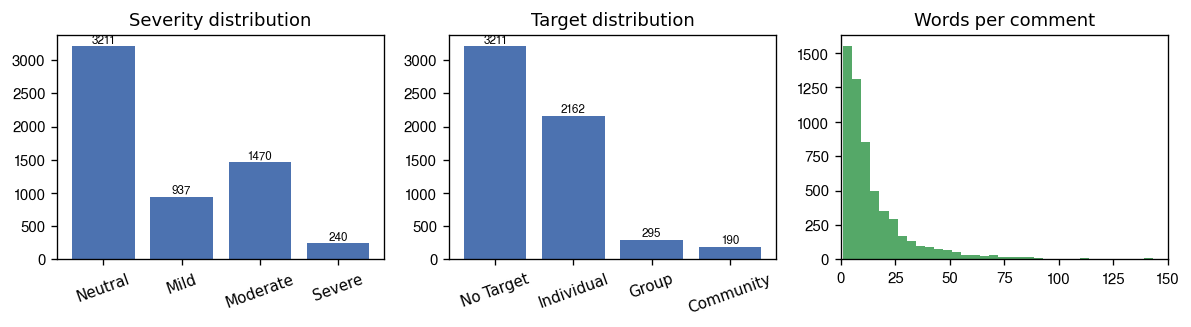

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
plt.rcParams.update({'font.size': 9, 'figure.dpi': 120})
if IN_COLAB:
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-beng', 'fonts-noto-core'], check=False)
for f in fm.findSystemFonts():
    if any(x in f.lower() for x in ['notosansbengali', 'lohit-bengali', 'lohit_bn', 'mukti', 'beng']):
        try: fm.fontManager.addfont(f)
        except Exception: pass
_bn = [f.name for f in fm.fontManager.ttflist
       if any(x in f.name.lower() for x in ['noto sans bengali', 'lohit bengali', 'mukti', 'bengali'])]
if _bn:
    plt.rcParams['font.family'] = [_bn[0], 'DejaVu Sans']; print('Bangla font:', _bn[0])
else:
    print('No Bangla font found, Bangla words may show as boxes')

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(RES, name + '.png'), dpi=300, bbox_inches='tight')
    fig.savefig(os.path.join(RES, name + '.pdf'), bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(1, 3, figsize=(10, 2.8))
for a, col, names, title in [(ax[0], 'sev', SEV_NAMES, 'Severity'), (ax[1], 'tgt', TGT_NAMES, 'Target')]:
    vc = df[col].value_counts().sort_index()
    a.bar(names, vc.values, color='#4C72B0'); a.set_title(title + ' distribution')
    for i, v in enumerate(vc.values): a.text(i, v, str(v), ha='center', va='bottom', fontsize=7)
    a.tick_params(axis='x', rotation=20)
ax[2].hist(df.text.str.split().str.len(), bins=50, color='#55A868')
ax[2].set_title('Words per comment'); ax[2].set_xlim(0, 150)
savefig(fig, 'fig_data_distribution')

In [ ]:
display(pd.crosstab(df.sev.map(dict(enumerate(SEV_NAMES))), df.tgt.map(dict(enumerate(TGT_NAMES))), margins=True)
        .rename_axis(index='Severity', columns='Target'))
display(pd.crosstab(df.Original_Label, df.sev.map(dict(enumerate(SEV_NAMES)))))

Target,Community,Group,Individual,No Target,All
Severity,,,,,
Mild,74,148,715,0,937
Moderate,107,128,1235,0,1470
Neutral,0,0,0,3211,3211
Severe,9,19,212,0,240
All,190,295,2162,3211,5858


sev,Mild,Moderate,Neutral,Severe
Original_Label,,,,
Neutral,46,14,1137,3
Political,251,208,609,8
Threat,73,544,401,173
sexual,136,554,452,52
troll,431,150,612,4


## 5. Data Splitting
Near-duplicate groups are rebuilt here, but the train/validation/test assignment is read from
`split_frozen_v5.csv`. The notebook stops if that file is missing, so a run can never create a new split and
produce numbers that cannot be compared with earlier runs.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# near-duplicate groups: texts that are almost the same must stay in the same split
V = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True).fit_transform(df.text)
S = cosine_similarity(V, dense_output=False); S.setdiag(0); S.eliminate_zeros()
n_comp, comp = connected_components(csr_matrix(S >= NEAR_DUP_SIM), directed=False)
df['group_id'] = pd.Series(comp).map(pd.Series(df.index).groupby(comp).max()).values
print(f'near-duplicate groups with more than one comment: {(pd.Series(comp).value_counts() > 1).sum()}')

# the split is read from file and never recomputed here, so every run uses the same train/val/test rows
sp = find_file(SPLIT_FILE)
assert sp is not None, f'{SPLIT_FILE} not found. Upload it before running; the split must not be recreated.'
split_col = pd.read_csv(sp)['split'].values
assert len(split_col) == len(df), 'split file has a different number of rows than the dataset'
assert set(split_col) == {'train', 'val', 'test'}, 'split file must contain only train, val and test'
df['split'] = split_col
print('split loaded from', sp)

assert df.groupby('group_id')['split'].nunique().max() == 1, 'duplicate group crosses splits'
for a, b in [('train', 'test'), ('train', 'val'), ('val', 'test')]:
    ov = set(df[df.split == a].text.str.lower()) & set(df[df.split == b].text.str.lower())
    assert not ov, f'text overlap {a}/{b}: {len(ov)}'
print('no duplicate group across splits, no train/val/test text overlap')

tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test'])
SPLIT_TAG = hashlib.md5(('|'.join(te.text) + '||' + '|'.join(va.text)).encode()).hexdigest()[:10]
if EXPECTED_SPLIT_ID:
    assert SPLIT_TAG == EXPECTED_SPLIT_ID, f'split id {SPLIT_TAG} does not match the expected {EXPECTED_SPLIT_ID}'
print(f'Train {len(tr)} | Val {len(va)} | Test {len(te)} | Total {len(df)} | split id {SPLIT_TAG}')
df[['split']].to_csv(os.path.join(RES, 'split_used.csv'), index=False)
display(pd.crosstab(df.split, df.sev.map(dict(enumerate(SEV_NAMES))), margins=True))
display(pd.crosstab(df.split, df.tgt.map(dict(enumerate(TGT_NAMES))), margins=True))


near-duplicate groups with more than one comment: 35
split loaded from split_frozen_v5.csv
no duplicate group across splits, no train/val/test text overlap
Train 4102 | Val 879 | Test 877 | Total 5858 | split id 0721b362d1


sev,Mild,Moderate,Neutral,Severe,All
split,,,,,
test,140,220,480,37,877
train,658,1030,2248,166,4102
val,139,220,483,37,879
All,937,1470,3211,240,5858


tgt,Community,Group,Individual,No Target,All
split,,,,,
test,28,43,326,480,877
train,135,209,1510,2248,4102
val,27,43,326,483,879
All,190,295,2162,3211,5858


## 6. Evaluation Functions
Severity and Target are reported separately. For Severity we also report the recall of the Severe class and
the ordinal error among the bullying grades. Joint evaluation checks whether both labels are correct for the
same comment.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             balanced_accuracy_score, confusion_matrix, classification_report)

def task_metrics(y, p, names, severe_idx=None):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    out = {'Accuracy': accuracy_score(y, p), 'Macro-P': pr, 'Macro-R': rc, 'Macro-F1': f1,
           'Weighted-F1': f1_score(y, p, average='weighted', zero_division=0),
           'Balanced-Acc': balanced_accuracy_score(y, p)}
    pcf = f1_score(y, p, average=None, labels=range(len(names)), zero_division=0)
    for n, v in zip(names, pcf): out[f'F1-{n}'] = v
    if severe_idx is not None:
        y, p = np.asarray(y), np.asarray(p)
        m = y == severe_idx
        out['Severe-Recall'] = (p[m] == severe_idx).mean() if m.any() else np.nan
        b = (y > 0) & (p > 0)                      # both say bullying -> distance between grades
        out['Ordinal-MAE (bullying)'] = np.abs(y[b] - p[b]).mean() if b.any() else np.nan
    return {k: round(float(v), 4) for k, v in out.items()}

def joint_metrics(ys, ps, yt, pt):
    ys, ps, yt, pt = map(np.asarray, (ys, ps, yt, pt))
    cs, ct = ys == ps, yt == pt
    return {'Joint exact-match': round(float((cs & ct).mean()), 4),
            'Sev ok / Tgt wrong': round(float((cs & ~ct).mean()), 4),
            'Sev wrong / Tgt ok': round(float((~cs & ct).mean()), 4),
            'Both wrong': round(float((~cs & ~ct).mean()), 4),
            'Pred consistency': round(float(((ps == 0) == (pt == 0)).mean()), 4)}

def plot_cm(y, p, names, title, fname):
    cm = confusion_matrix(y, p, labels=range(len(names)))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(3.4, 3))
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f'{cm[i,j]}\n{cmn[i,j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if cmn[i, j] > .6 else 'black')
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha='right')
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title, fontsize=8)
    savefig(fig, fname)

RESULTS = []
def record(system, family, task, split, y, p):
    names, sidx = (SEV_NAMES, 3) if task == 'sev' else (TGT_NAMES, None)
    r = {'System': system, 'Family': family, 'Task': 'Severity' if task == 'sev' else 'Target', 'Split': split}
    r.update(task_metrics(y, p, names, sidx)); RESULTS.append(r); return r

## 7. Baseline Model: TF-IDF + Linear SVM
Word (1-2 gram) and character (2-5 gram) TF-IDF features. `C` is selected on the validation set.
The baseline is reported with the raw `LinearSVC` predictions; the calibrated probabilities are used only as
ensemble input. `Original_Label` is never used as a feature.

In [ ]:
from sklearn.pipeline import make_union
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

def tfidf_prep(t):
    t = re.sub(r'https?://\S+', ' URL ', str(t).lower())
    return re.sub(r'\s+', ' ', t).strip()

feats = make_union(
    TfidfVectorizer(preprocessor=tfidf_prep, analyzer='word', ngram_range=(1, 2), min_df=2,
                    sublinear_tf=True, token_pattern=r'\S+'),
    TfidfVectorizer(preprocessor=tfidf_prep, analyzer='char_wb', ngram_range=(2, 5), min_df=2,
                    sublinear_tf=True, max_features=200000))
Xtr = feats.fit_transform(tr.text); Xva = feats.transform(va.text); Xte = feats.transform(te.text)

SVM_RAW_PRED = {}
PROBS = {}                       # PROBS[system][task] = {'val': array, 'test': array}
for task in ['sev', 'tgt']:
    best = None
    for C in [0.03, 0.1, 0.3, 1.0, 3.0]:
        m = LinearSVC(C=C, class_weight='balanced', max_iter=5000).fit(Xtr, tr[task])
        f = f1_score(va[task], m.predict(Xva), average='macro')
        if best is None or f > best[0]: best = (f, C)
    print(f'{task}: best C={best[1]} (val Macro-F1={best[0]:.4f})')
    cal = CalibratedClassifierCV(LinearSVC(C=best[1], class_weight='balanced', max_iter=5000), cv=5).fit(Xtr, tr[task])
    PROBS.setdefault('TF-IDF+SVM', {})[task] = {'val': cal.predict_proba(Xva), 'test': cal.predict_proba(Xte)}
    raw = LinearSVC(C=best[1], class_weight='balanced', max_iter=5000).fit(Xtr, tr[task])
    SVM_RAW_PRED.setdefault(task, {})
    for split, X_, d_ in [('val', Xva, va), ('test', Xte, te)]:
        SVM_RAW_PRED[task][split] = raw.predict(X_)
        record('TF-IDF+SVM', 'Baseline', task, split, d_[task], SVM_RAW_PRED[task][split])
display(pd.DataFrame(RESULTS).query("Split=='test'"))

sev: best C=0.3 (val Macro-F1=0.7554)
tgt: best C=0.1 (val Macro-F1=0.5647)


,System,Family,Task,Split,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-F1,Balanced-Acc,F1-Neutral,F1-Mild,F1-Moderate,F1-Severe,Severe-Recall,Ordinal-MAE (bullying),F1-No Target,F1-Individual,F1-Group,F1-Community
1,TF-IDF+SVM,Baseline,Severity,test,0.8130,0.7645,0.7090,0.7332,0.8093,0.7090,0.8694,0.7019,0.7857,0.5758,0.5135,0.1097,NaN,NaN,NaN,NaN
3,TF-IDF+SVM,Baseline,Target,test,0.7845,0.6322,0.5755,0.5976,0.7784,0.5755,NaN,NaN,NaN,NaN,NaN,NaN,0.8563,0.7476,0.3951,0.3913


## 8. Transformer Models
One shared implementation for single-task and multi-task. Encoder (BanglaBERT / XLM-R / mBERT) with mean pooling
over the attention mask, dropout 0.1 and one linear head per task (4 classes).
Multi-task loss = `w_sev * CE_sev + w_tgt * CE_tgt`. The gold label of one task is never given as input to the other.
Class imbalance is handled with sqrt inverse-frequency class weights, and the best epoch is chosen on validation
Macro-F1 only.

In [ ]:
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch import nn
from torch.utils.data import DataLoader, Dataset
import unicodedata

try:
    from normalizer import normalize as bn_normalize
    print('csebuetnlp normalizer loaded')
except Exception:
    bn_normalize = None
    print('normalizer not available, BanglaBERT input is only NFC normalized')

def prep_for(model_name, texts):
    if model_name == 'BanglaBERT' and bn_normalize is not None:
        return [bn_normalize(t) for t in texts]
    return [unicodedata.normalize('NFC', t) for t in texts]

class TextDS(Dataset):
    def __init__(self, enc, labels): self.enc, self.labels = enc, labels
    def __len__(self): return len(self.enc['input_ids'])
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        for t, y in self.labels.items(): item['y_' + t] = torch.tensor(int(y[i]))
        return item

def collate(batch, pad_id):
    L = max(len(b['input_ids']) for b in batch)
    out = {}
    for k in batch[0]:
        if k.startswith('y_'): out[k] = torch.stack([b[k] for b in batch])
        else:
            pad = pad_id if k == 'input_ids' else 0
            out[k] = torch.stack([torch.cat([b[k], torch.full((L - len(b[k]),), pad, dtype=b[k].dtype)]) for b in batch])
    return out

class MultiHeadClassifier(nn.Module):
    def __init__(self, checkpoint, tasks, n_classes=4, dropout=0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(checkpoint)
        h = self.encoder.config.hidden_size
        self.tasks = list(tasks)
        self.drop = nn.Dropout(dropout)
        self.heads = nn.ModuleDict({t: nn.Linear(h, n_classes) for t in self.tasks})
    def forward(self, input_ids, attention_mask, token_type_ids=None):
        kw = {'input_ids': input_ids, 'attention_mask': attention_mask}
        if token_type_ids is not None and getattr(self.encoder.config, 'type_vocab_size', 0) > 1:
            kw['token_type_ids'] = token_type_ids
        hs = self.encoder(**kw).last_hidden_state
        m = attention_mask.unsqueeze(-1).float()
        pooled = self.drop((hs * m).sum(1) / m.sum(1).clamp(min=1e-6))
        return {t: self.heads[t](pooled) for t in self.tasks}

def class_weights(y, k=4):
    c = np.bincount(y, minlength=k).astype(float)
    w = 1 / np.sqrt(np.maximum(c, 1)); w = w / w.mean()
    return torch.tensor(w, dtype=torch.float)

def encode(tok, texts):
    return tok(texts, truncation=True, max_length=MAX_LEN)

@torch.no_grad()
def predict_probs(model, tok, texts, model_name, bs=64):
    model.eval(); out = {t: [] for t in model.tasks}
    texts = prep_for(model_name, list(texts))
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt').to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
            logits = model(**{k: v for k, v in enc.items() if k in ('input_ids', 'attention_mask', 'token_type_ids')})
        for t in model.tasks: out[t].append(torch.softmax(logits[t].float(), -1).cpu().numpy())
    return {t: np.concatenate(v) for t, v in out.items()}

csebuetnlp normalizer loaded


In [ ]:
def train_transformer(model_name, tasks, save_ckpt=False):
    checkpoint, lr = MODELS[model_name]
    set_seed()
    tok = AutoTokenizer.from_pretrained(checkpoint)
    model = MultiHeadClassifier(checkpoint, tasks).to(DEVICE)
    enc_tr = encode(tok, prep_for(model_name, tr.text.tolist()))
    trunc = np.mean([len(x) >= MAX_LEN for x in enc_tr['input_ids']])
    print(f'  {model_name} {tasks}: {100*trunc:.1f}% train texts truncated at {MAX_LEN} tokens')
    ds = TextDS(enc_tr, {t: tr[t].values for t in tasks})
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                    collate_fn=lambda b: collate(b, tok.pad_token_id),
                    generator=torch.Generator().manual_seed(SEED))
    lossf = {t: nn.CrossEntropyLoss(weight=class_weights(tr[t].values).to(DEVICE) if USE_CLASS_WEIGHTS else None)
             for t in tasks}
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    steps = len(dl) * EPOCHS
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
    best, best_state, bad, log = -1, None, 0, []
    for ep in range(1, EPOCHS + 1):
        model.train(); tl, t0 = 0.0, time.time()
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
                out = model(**{k: v for k, v in b.items() if k in ('input_ids', 'attention_mask', 'token_type_ids')})
                loss = sum(LOSS_W[t] * lossf[t](out[t].float(), b['y_' + t]) for t in tasks)
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step(); tl += loss.item()
        vp = predict_probs(model, tok, va.text, model_name)
        vf = {t: f1_score(va[t], vp[t].argmax(1), average='macro') for t in tasks}
        score = float(np.mean(list(vf.values())))
        log.append({'epoch': ep, 'train_loss': tl / len(dl), **{f'val_F1_{t}': v for t, v in vf.items()}})
        print(f'    ep{ep} loss={tl/len(dl):.4f} val Macro-F1={vf} ({time.time()-t0:.0f}s)')
        if score > best:
            best, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print('    early stop'); break
    model.load_state_dict(best_state)
    pv, pt = predict_probs(model, tok, va.text, model_name), predict_probs(model, tok, te.text, model_name)
    if save_ckpt:
        torch.save(best_state, os.path.join(CKPT, f'{model_name}_{"+".join(tasks)}.pt'))
    del best_state
    return model, tok, pv, pt, pd.DataFrame(log)

### 8.1 Training all runs
Three backbones x (single-task Severity, single-task Target, multi-task) = 9 runs. Probabilities are cached in
`predictions/`, so a re-run skips training. A cached file is only reused if it was produced with the same split.

In [ ]:
TRAIN_LOGS = {}
def run_key(name, tasks): return f'{name}_{"+".join(tasks)}_final'

for name in MODELS:
    for tasks, family in [(('sev',), 'Single-task'), (('tgt',), 'Single-task'), (('sev', 'tgt'), 'Multi-task')]:
        key = run_key(name, tasks); f = os.path.join(PRED, key + '.npz')
        cached = None
        if os.path.exists(f):
            z = np.load(f, allow_pickle=True)
            if str(z['split_tag']) == SPLIT_TAG: cached = z
            else: print('cache ignored (different split):', key)
        if cached is not None:
            print('cached', key)
            pv = {t: cached['val_' + t] for t in tasks}; pt = {t: cached['test_' + t] for t in tasks}
        else:
            print('training', key)
            model, tok, pv, pt, log = train_transformer(name, tasks, save_ckpt=(name == XAI_MODEL and len(tasks) == 2))
            TRAIN_LOGS[key] = log; log.to_csv(os.path.join(RES, f'trainlog_{key}.csv'), index=False)
            np.savez(f, split_tag=SPLIT_TAG,
                     **{f'val_{t}': pv[t] for t in tasks}, **{f'test_{t}': pt[t] for t in tasks})
            del model
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        sysname = f'{name} ({"MTL" if len(tasks) == 2 else "ST"})'
        for t in tasks:
            PROBS.setdefault(sysname, {})[t] = {'val': pv[t], 'test': pt[t]}
            for split, d_ in [('val', va), ('test', te)]:
                record(sysname, family, t, split, d_[t], pv[t].argmax(1) if split == 'val' else pt[t].argmax(1))

R = pd.DataFrame(RESULTS)
display(R.query("Split=='test'")[['System', 'Task', 'Accuracy', 'Macro-F1', 'Weighted-F1', 'Balanced-Acc']])

training BanglaBERT_sev_final


config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/528k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

... (39 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  mBERT ('sev', 'tgt'): 8.0% train texts truncated at 128 tokens
    ep1 loss=2.2222 val Macro-F1={'sev': 0.6498667163778487, 'tgt': 0.4226485762604127} (43s)
    ep2 loss=1.4655 val Macro-F1={'sev': 0.7351773435311577, 'tgt': 0.522186925188134} (44s)
    ep3 loss=1.0281 val Macro-F1={'sev': 0.7468502356984998, 'tgt': 0.5690461614500241} (44s)
    ep4 loss=0.7250 val Macro-F1={'sev': 0.7533987762859657, 'tgt': 0.6029099552755729} (44s)
    ep5 loss=0.4943 val Macro-F1={'sev': 0.7271672053910505, 'tgt': 0.6145043988181244} (43s)
    ep6 loss=0.3443 val Macro-F1={'sev': 0.7401941003787817, 'tgt': 0.6070632217625037} (44s)
    early stop


,System,Task,Accuracy,Macro-F1,Weighted-F1,Balanced-Acc
1,TF-IDF+SVM,Severity,0.8130,0.7332,0.8093,0.7090
3,TF-IDF+SVM,Target,0.7845,0.5976,0.7784,0.5755
5,BanglaBERT (ST),Severity,0.8290,0.7396,0.8262,0.7198
7,BanglaBERT (ST),Target,0.8301,0.6322,0.8326,0.6322
9,BanglaBERT (MTL),Severity,0.8198,0.7356,0.8229,0.7535
11,BanglaBERT (MTL),Target,0.8347,0.6576,0.8350,0.6659
13,XLM-R (ST),Severity,0.7993,0.7239,0.8002,0.7320
15,XLM-R (ST),Target,0.7754,0.6167,0.7816,0.6494
17,XLM-R (MTL),Severity,0.8096,0.7301,0.8094,0.7368
19,XLM-R (MTL),Target,0.7936,0.6149,0.7943,0.6242


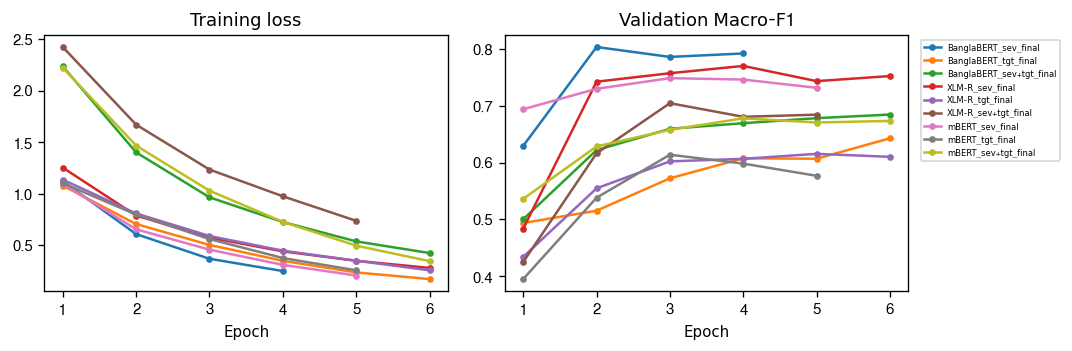

In [ ]:
logs = {k: pd.read_csv(os.path.join(RES, f'trainlog_{k}.csv')) for k in
        [run_key(n, t) for n in MODELS for t in [('sev',), ('tgt',), ('sev', 'tgt')]]
        if os.path.exists(os.path.join(RES, f'trainlog_{k}.csv'))}
if logs:
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    for k, lg in logs.items():
        ax[0].plot(lg.epoch, lg.train_loss, marker='o', ms=3, label=k)
        vcols = [c for c in lg if c.startswith('val_F1')]
        ax[1].plot(lg.epoch, lg[vcols].mean(1), marker='o', ms=3, label=k)
    ax[0].set_title('Training loss'); ax[1].set_title('Validation Macro-F1')
    ax[0].set_xlabel('Epoch'); ax[1].set_xlabel('Epoch')
    ax[1].legend(fontsize=5, ncol=1, bbox_to_anchor=(1.02, 1), loc='upper left')
    savefig(fig, 'fig_training_curves')

## 9. Ensemble Models
Per task: soft voting, weighted soft voting (weight grid step 0.1, weights taken from validation only, scored
out-of-fold) and stacking (logistic regression on the validation probabilities, out-of-fold validation score).
Families: ST-Ens (3 single-task), MTL-Ens (3 multi-task), All-Ens (all transformers + calibrated SVM).

In [ ]:
from itertools import product
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def weight_grid(n, step=0.1):
    k = int(round(1 / step))
    for c in product(range(k + 1), repeat=n):
        if sum(c) == k: yield np.array(c) / k

ENS_INFO = []
def ensembles(members, label, task):
    members = [m for m in members if m in PROBS and task in PROBS[m]]
    if len(members) < 2: return
    V = [PROBS[m][task]['val'] for m in members]; T = [PROBS[m][task]['test'] for m in members]
    yv = va[task].values
    PROBS.setdefault(f'{label} SoftVote', {})[task] = {'val': np.mean(V, 0), 'test': np.mean(T, 0)}

    Va = np.stack(V); grid = list(weight_grid(len(members)))
    def pick(idx):
        return max(grid, key=lambda w: f1_score(yv[idx], np.tensordot(w, Va[:, idx], 1).argmax(1), average='macro'))
    best = pick(np.arange(len(yv)))                       # weights for the test set: all validation rows
    oof_w = np.zeros_like(Va[0])                          # validation score must be out-of-fold
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Va[0], yv):
        oof_w[b] = np.tensordot(pick(a), Va[:, b], 1)
    PROBS.setdefault(f'{label} WeightedVote', {})[task] = {'val': oof_w, 'test': np.tensordot(best, T, 1)}
    ENS_INFO.append({'Ensemble': f'{label} WeightedVote', 'Task': task, **dict(zip(members, best.round(2)))})

    Xv, Xt = np.hstack(V), np.hstack(T)
    meta = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=5, max_iter=2000, class_weight='balanced',
                                scoring='f1_macro', random_state=SEED).fit(Xv, yv)
    oof = cross_val_predict(LogisticRegression(C=meta.C_[0], max_iter=2000, class_weight='balanced'),
                            Xv, yv, cv=5, method='predict_proba')
    PROBS.setdefault(f'{label} Stacking', {})[task] = {'val': oof, 'test': meta.predict_proba(Xt)}

ST  = [f'{n} (ST)' for n in MODELS]
MTL = [f'{n} (MTL)' for n in MODELS]
for task in ['sev', 'tgt']:
    ensembles(ST, 'ST-Ens', task); ensembles(MTL, 'MTL-Ens', task)
    ensembles(ST + MTL + ['TF-IDF+SVM'], 'All-Ens', task)
for s in [k for k in PROBS if 'Ens' in k]:
    for t in PROBS[s]:
        for split, d_ in [('val', va), ('test', te)]:
            record(s, 'Ensemble', t, split, d_[t], PROBS[s][t][split].argmax(1))
display(pd.DataFrame(ENS_INFO))

,Ensemble,Task,BanglaBERT (ST),XLM-R (ST),mBERT (ST),BanglaBERT (MTL),XLM-R (MTL),mBERT (MTL),TF-IDF+SVM
0,ST-Ens WeightedVote,sev,0.7,0.0,0.3,NaN,NaN,NaN,NaN
1,MTL-Ens WeightedVote,sev,NaN,NaN,NaN,0.8,0.0,0.2,NaN
2,All-Ens WeightedVote,sev,0.4,0.1,0.2,0.1,0.0,0.0,0.2
3,ST-Ens WeightedVote,tgt,0.5,0.2,0.3,NaN,NaN,NaN,NaN
4,MTL-Ens WeightedVote,tgt,NaN,NaN,NaN,0.2,0.7,0.1,NaN
5,All-Ens WeightedVote,tgt,0.1,0.2,0.0,0.1,0.6,0.0,0.0


## 10. Results
The best system for each task is selected on validation Macro-F1, never on the test set.

In [ ]:
R = pd.DataFrame(RESULTS).drop_duplicates(['System', 'Task', 'Split'], keep='last')
for task in ['Severity', 'Target']:
    cols = ['System', 'Family', 'Accuracy', 'Macro-P', 'Macro-R', 'Macro-F1', 'Weighted-F1', 'Balanced-Acc'] + \
           (['Severe-Recall', 'Ordinal-MAE (bullying)'] if task == 'Severity' else [])
    t = R[(R.Task == task) & (R.Split == 'test')][cols].sort_values('Macro-F1', ascending=False)
    print(f'\n=== {task} - TEST ==='); display(t.reset_index(drop=True))

with pd.ExcelWriter(os.path.join(RES, 'all_results.xlsx')) as w:
    R.to_excel(w, sheet_name='all_metrics', index=False)
    pd.DataFrame(ENS_INFO).to_excel(w, sheet_name='ensemble_weights', index=False)

BEST = {}
for task, tn in [('sev', 'Severity'), ('tgt', 'Target')]:
    v = R[(R.Task == tn) & (R.Split == 'val')]
    BEST[task] = v.sort_values('Macro-F1', ascending=False).System.iloc[0]
print('Best by validation Macro-F1 ->', BEST)


=== Severity - TEST ===


,System,Family,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-F1,Balanced-Acc,Severe-Recall,Ordinal-MAE (bullying)
0,All-Ens Stacking,Ensemble,0.8529,0.7730,0.7893,0.7803,0.8541,0.7893,0.5946,0.1108
1,ST-Ens Stacking,Ensemble,0.8461,0.7693,0.7943,0.7796,0.8481,0.7943,0.6216,0.1028
2,All-Ens WeightedVote,Ensemble,0.8426,0.7890,0.7471,0.7635,0.8409,0.7471,0.4865,0.1137
3,ST-Ens SoftVote,Ensemble,0.8438,0.7734,0.7512,0.7616,0.8423,0.7512,0.5405,0.1065
4,mBERT (ST),Single-task,0.8301,0.7506,0.7612,0.7543,0.8307,0.7612,0.6216,0.1147
5,All-Ens SoftVote,Ensemble,0.8426,0.7718,0.7370,0.7526,0.8404,0.7370,0.4865,0.1128
6,ST-Ens WeightedVote,Ensemble,0.8324,0.8018,0.7288,0.7510,0.8301,0.7288,0.4324,0.1176
7,MTL-Ens Stacking,Ensemble,0.8278,0.7309,0.7772,0.7504,0.8314,0.7772,0.6486,0.1528
8,MTL-Ens SoftVote,Ensemble,0.8358,0.7481,0.7345,0.7410,0.8348,0.7345,0.4865,0.1420
9,BanglaBERT (ST),Single-task,0.8290,0.7865,0.7198,0.7396,0.8262,0.7198,0.4054,0.1320



=== Target - TEST ===


,System,Family,Accuracy,Macro-P,Macro-R,Macro-F1,Weighted-F1,Balanced-Acc
0,ST-Ens SoftVote,Ensemble,0.8198,0.6546,0.6834,0.6678,0.8221,0.6834
1,BanglaBERT (MTL),Multi-task,0.8347,0.6570,0.6659,0.6576,0.8350,0.6659
2,ST-Ens Stacking,Ensemble,0.8176,0.6319,0.6970,0.6572,0.8240,0.6970
3,ST-Ens WeightedVote,Ensemble,0.8381,0.6548,0.6541,0.6529,0.8395,0.6541
4,MTL-Ens Stacking,Ensemble,0.8073,0.6211,0.7048,0.6455,0.8202,0.7048
5,MTL-Ens WeightedVote,Ensemble,0.8176,0.6416,0.6489,0.6440,0.8179,0.6489
6,All-Ens SoftVote,Ensemble,0.8369,0.6466,0.6406,0.6434,0.8366,0.6406
7,MTL-Ens SoftVote,Ensemble,0.8301,0.6395,0.6432,0.6413,0.8303,0.6432
8,All-Ens WeightedVote,Ensemble,0.8096,0.6270,0.6448,0.6346,0.8107,0.6448
9,BanglaBERT (ST),Single-task,0.8301,0.6384,0.6322,0.6322,0.8326,0.6322


Best by validation Macro-F1 -> {'sev': 'ST-Ens WeightedVote', 'tgt': 'All-Ens SoftVote'}


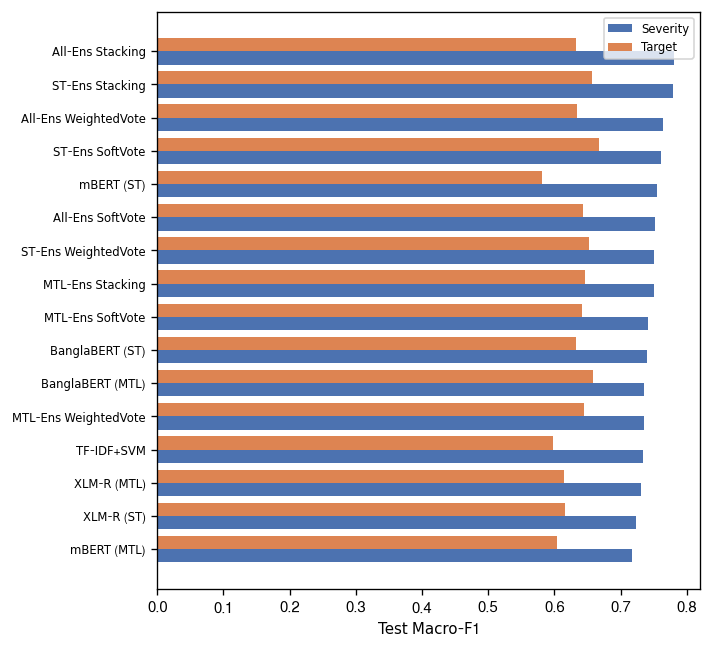

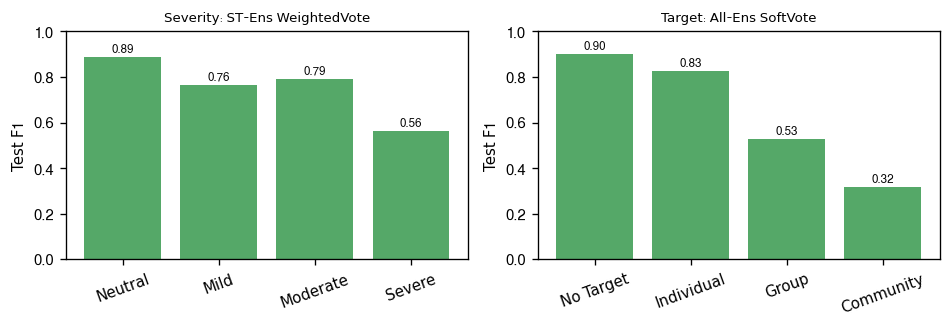

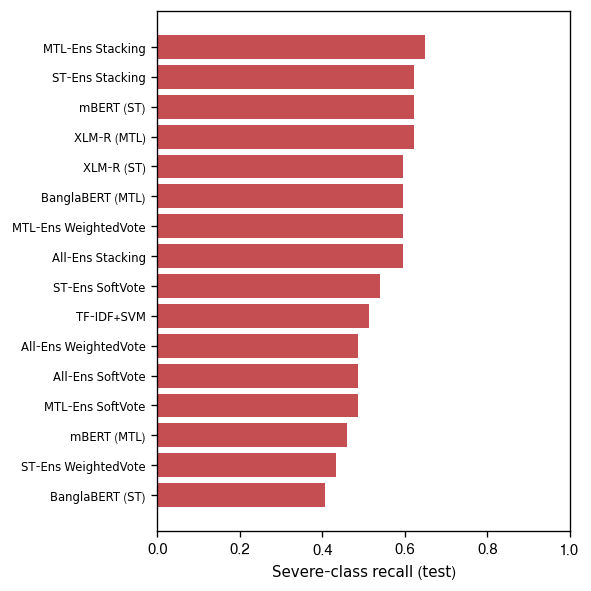

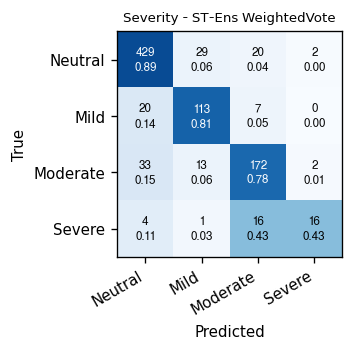

              precision    recall  f1-score   support

     Neutral     0.8827    0.8938    0.8882       480
        Mild     0.7244    0.8071    0.7635       140
    Moderate     0.8000    0.7818    0.7908       220
      Severe     0.8000    0.4324    0.5614        37

    accuracy                         0.8324       877
   macro avg     0.8018    0.7288    0.7510       877
weighted avg     0.8332    0.8324    0.8301       877



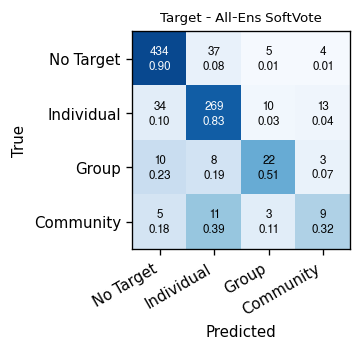

              precision    recall  f1-score   support

   No Target     0.8986    0.9042    0.9013       480
  Individual     0.8277    0.8252    0.8264       326
       Group     0.5500    0.5116    0.5301        43
   Community     0.3103    0.3214    0.3158        28

    accuracy                         0.8369       877
   macro avg     0.6466    0.6406    0.6434       877
weighted avg     0.8363    0.8369    0.8366       877



In [ ]:
P = R[R.Split == 'test'].pivot_table(index='System', columns='Task', values='Macro-F1')
order = R[(R.Split == 'test') & (R.Task == 'Severity')].sort_values('Macro-F1').System
P = P.reindex([s for s in order if s in P.index])
fig, ax = plt.subplots(figsize=(6, 0.28 * len(P) + 1))
y = np.arange(len(P))
ax.barh(y - 0.2, P['Severity'], 0.4, label='Severity', color='#4C72B0')
ax.barh(y + 0.2, P['Target'], 0.4, label='Target', color='#DD8452')
ax.set_yticks(y); ax.set_yticklabels(P.index, fontsize=7)
ax.set_xlabel('Test Macro-F1'); ax.legend(fontsize=7)
savefig(fig, 'fig_model_comparison')

fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for a, task, tn, names in [(ax[0], 'sev', 'Severity', SEV_NAMES), (ax[1], 'tgt', 'Target', TGT_NAMES)]:
    row = R[(R.System == BEST[task]) & (R.Task == tn) & (R.Split == 'test')].iloc[0]
    vals = [row[f'F1-{n}'] for n in names]
    a.bar(names, vals, color='#55A868'); a.set_ylim(0, 1); a.set_title(f'{tn}: {BEST[task]}', fontsize=8)
    for i, v in enumerate(vals): a.text(i, v + .02, f'{v:.2f}', ha='center', fontsize=7)
    a.tick_params(axis='x', rotation=20); a.set_ylabel('Test F1')
savefig(fig, 'fig_classwise_f1')

sr = R[(R.Task == 'Severity') & (R.Split == 'test')].sort_values('Severe-Recall')
fig, ax = plt.subplots(figsize=(5, 0.25 * len(sr) + 1))
ax.barh(sr.System, sr['Severe-Recall'], color='#C44E52')
ax.set_xlabel('Severe-class recall (test)'); ax.set_xlim(0, 1); ax.tick_params(axis='y', labelsize=7)
savefig(fig, 'fig_severe_recall')

for task, names, tn in [('sev', SEV_NAMES, 'Severity'), ('tgt', TGT_NAMES, 'Target')]:
    p = PROBS[BEST[task]][task]['test'].argmax(1)
    plot_cm(te[task], p, names, f'{tn} - {BEST[task]}', f'fig_cm_{task}_best')
    print(classification_report(te[task], p, target_names=names, digits=4))

### 10.1 Joint evaluation and single-task vs multi-task
Joint: Severity and Target both correct on the same comment. Prediction consistency checks the dataset rule
No Target <-> Neutral.

In [ ]:
J = []
pairs = [(f'{n} (ST)', f'{n} (ST)') for n in MODELS] + [(f'{n} (MTL)', f'{n} (MTL)') for n in MODELS] + \
        [('ST-Ens WeightedVote',) * 2, ('MTL-Ens WeightedVote',) * 2, ('All-Ens WeightedVote',) * 2,
         ('TF-IDF+SVM',) * 2, (BEST['sev'], BEST['tgt'])]
for s_sys, t_sys in pairs:
    if s_sys in PROBS and t_sys in PROBS and 'sev' in PROBS[s_sys] and 'tgt' in PROBS[t_sys]:
        ps, pt = PROBS[s_sys]['sev']['test'].argmax(1), PROBS[t_sys]['tgt']['test'].argmax(1)
        J.append({'Severity system': s_sys, 'Target system': t_sys, **joint_metrics(te.sev, ps, te.tgt, pt)})
J = pd.DataFrame(J).drop_duplicates(); display(J)
J.to_csv(os.path.join(RES, 'table_joint_eval.csv'), index=False)

rq3 = []
for n in MODELS:
    for tn in ['Severity', 'Target']:
        g = R[(R.Split == 'test') & (R.Task == tn)].set_index('System')
        if f'{n} (ST)' in g.index and f'{n} (MTL)' in g.index:
            rq3.append({'Backbone': n, 'Task': tn,
                        'ST Macro-F1': g.loc[f'{n} (ST)', 'Macro-F1'],
                        'MTL Macro-F1': g.loc[f'{n} (MTL)', 'Macro-F1'],
                        'Delta (MTL-ST)': round(g.loc[f'{n} (MTL)', 'Macro-F1'] - g.loc[f'{n} (ST)', 'Macro-F1'], 4)})
rq3 = pd.DataFrame(rq3); display(rq3)
rq3.to_csv(os.path.join(RES, 'table_rq3_st_vs_mtl.csv'), index=False)

,Severity system,Target system,Joint exact-match,Sev ok / Tgt wrong,Sev wrong / Tgt ok,Both wrong,Pred consistency
0,BanglaBERT (ST),BanglaBERT (ST),0.7457,0.0832,0.0844,0.0867,0.9282
1,XLM-R (ST),XLM-R (ST),0.6887,0.1106,0.0867,0.1140,0.8951
2,mBERT (ST),mBERT (ST),0.7092,0.1209,0.0513,0.1186,0.9145
3,BanglaBERT (MTL),BanglaBERT (MTL),0.7719,0.0479,0.0627,0.1174,0.9909
4,XLM-R (MTL),XLM-R (MTL),0.7343,0.0753,0.0593,0.1311,0.9544
5,mBERT (MTL),mBERT (MTL),0.7446,0.0661,0.0479,0.1414,0.9806
6,ST-Ens WeightedVote,ST-Ens WeightedVote,0.7560,0.0764,0.0821,0.0855,0.9316
7,MTL-Ens WeightedVote,MTL-Ens WeightedVote,0.7218,0.0981,0.0958,0.0844,0.8962
8,All-Ens WeightedVote,All-Ens WeightedVote,0.7469,0.0958,0.0627,0.0946,0.9225
9,TF-IDF+SVM,TF-IDF+SVM,0.7309,0.0775,0.0616,0.1300,0.9225


,Backbone,Task,ST Macro-F1,MTL Macro-F1,Delta (MTL-ST)
0,BanglaBERT,Severity,0.7396,0.7356,-0.0040
1,BanglaBERT,Target,0.6322,0.6576,0.0254
2,XLM-R,Severity,0.7239,0.7301,0.0062
3,XLM-R,Target,0.6167,0.6149,-0.0018
4,mBERT,Severity,0.7543,0.7167,-0.0376
5,mBERT,Target,0.5819,0.6034,0.0215


### 10.2 Error analysis
Wrong predictions are written to `errors_test.csv` with the comment text. `Original_Label` is used here only for
analysis, never as a feature.

In [ ]:
err = te[['id', 'text', 'Original_Label', 'sev', 'tgt']].copy()
err['pred_sev'] = PROBS[BEST['sev']]['sev']['test'].argmax(1)
err['pred_tgt'] = PROBS[BEST['tgt']]['tgt']['test'].argmax(1)
err['conf_sev'] = PROBS[BEST['sev']]['sev']['test'].max(1).round(3)
for c, names in [('sev', SEV_NAMES), ('pred_sev', SEV_NAMES), ('tgt', TGT_NAMES), ('pred_tgt', TGT_NAMES)]:
    err[c + '_name'] = err[c].map(dict(enumerate(names)))
err['sev_wrong'] = err.sev != err.pred_sev
err['tgt_wrong'] = err.tgt != err.pred_tgt
err[err.sev_wrong | err.tgt_wrong].to_csv(os.path.join(RES, 'errors_test.csv'), index=False, encoding='utf-8-sig')
display(err.groupby('Original_Label')[['sev_wrong', 'tgt_wrong']].mean().round(3).rename(columns=lambda c: c + ' rate'))
err['len_bin'] = pd.cut(err.text.str.split().str.len(), [0, 5, 15, 40, 10000], labels=['1-5', '6-15', '16-40', '40+'])
display(err.groupby('len_bin', observed=False)[['sev_wrong', 'tgt_wrong']].mean().round(3))
print('Most common severity confusions:')
display(err[err.sev_wrong].groupby(['sev_name', 'pred_sev_name']).size().sort_values(ascending=False).head(8))

,sev_wrong rate,tgt_wrong rate
Original_Label,,
Neutral,0.059,0.053
Political,0.149,0.234
Threat,0.209,0.164
sexual,0.269,0.198
troll,0.144,0.161


,sev_wrong,tgt_wrong
len_bin,,
1-5,0.120,0.079
6-15,0.160,0.160
16-40,0.228,0.228
40+,0.214,0.300


Most common severity confusions:


,,0
sev_name,pred_sev_name,
Moderate,Neutral,33
Neutral,Mild,29
Mild,Neutral,20
Neutral,Moderate,20
Severe,Moderate,16
Moderate,Mild,13
Mild,Moderate,7
Severe,Neutral,4


## 11. Explainability: SHAP and LIME
The multi-task `XAI_MODEL` is reloaded and both outputs (Severity, Target) are explained at word level
(whitespace tokens), so SHAP and LIME use the same unit and can be compared.

In [ ]:
import shap
from lime.lime_text import LimeTextExplainer

ck = os.path.join(CKPT, f'{XAI_MODEL}_sev+tgt.pt')
xai_tok = AutoTokenizer.from_pretrained(MODELS[XAI_MODEL][0])
xai_model = MultiHeadClassifier(MODELS[XAI_MODEL][0], ('sev', 'tgt')).to(DEVICE)
if os.path.exists(ck):
    xai_model.load_state_dict(torch.load(ck, map_location=DEVICE))
else:
    print('No checkpoint (cached run), re-training the XAI model')
    xai_model, xai_tok, _, _, _ = train_transformer(XAI_MODEL, ('sev', 'tgt'), save_ckpt=True)
xai_model.eval()

def make_predict(task):
    def f(texts):
        texts = [t if isinstance(t, str) else str(t) for t in list(texts)]
        texts = [t if t.strip() else '।' for t in texts]
        return predict_probs(xai_model, xai_tok, texts, XAI_MODEL)[task]
    return f
predict_fn = {'sev': make_predict('sev'), 'tgt': make_predict('tgt')}

rng = np.random.RandomState(SEED)
pv = predict_probs(xai_model, xai_tok, te.text, XAI_MODEL)
cand = te.assign(ps=pv['sev'].argmax(1), pt=pv['tgt'].argmax(1), nw=te.text.str.split().str.len())
cand = cand[(cand.nw >= 3) & (cand.nw <= 40)]
picks = []
for c in range(4):
    for correct in [True, False]:
        g = cand[(cand.sev == c) & ((cand.ps == cand.sev) == correct)]
        picks += list(g.sample(min(len(g), XAI_N_EXAMPLES // 8), random_state=SEED).index)
XAI = cand.loc[picks].reset_index(drop=True)
print('XAI examples:', len(XAI)); display(pd.crosstab(XAI.sev, XAI.ps == XAI.sev))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


XAI examples: 141


col_0,False,True
sev,,
0,18,18
1,18,18
2,18,18
3,15,18


In [ ]:
lime_exp = LimeTextExplainer(class_names=SEV_NAMES, split_expression=r'\s+', bow=False, random_state=SEED)
def lime_weights(text, task, label, num_samples=500, seed=SEED):
    e = LimeTextExplainer(split_expression=r'\s+', bow=False, random_state=seed)
    ex = e.explain_instance(text, predict_fn[task], labels=[label],
                            num_features=len(text.split()), num_samples=num_samples)
    words = text.split()
    w = np.zeros(len(words))
    for idx, val in ex.as_map()[label]: w[idx] = val
    return w

masker = shap.maskers.Text(r'\s+')
shap_expl = {t: shap.Explainer(predict_fn[t], masker, output_names=(SEV_NAMES if t == 'sev' else TGT_NAMES))
             for t in ['sev', 'tgt']}
def shap_weights(text, task, label, max_evals=300):
    sv = shap_expl[task]([text], max_evals=max_evals, silent=True)
    toks = [t.strip() for t in sv.data[0]]
    vals = sv.values[0][:, label]
    keep = [i for i, t in enumerate(toks) if t]
    return np.array([vals[i] for i in keep]), [toks[i] for i in keep]

EXPL = []
for i, r in XAI.iterrows():
    for task, lab_true, lab_pred in [('sev', r.sev, r.ps), ('tgt', r.tgt, r.pt)]:
        words = r.text.split()
        lw = lime_weights(r.text, task, int(lab_pred))
        sw, stoks = shap_weights(r.text, task, int(lab_pred))
        if len(stoks) != len(words): sw = None      # tokenisation mismatch, skip SHAP word alignment
        EXPL.append({'i': i, 'task': task, 'text': r.text, 'words': words,
                     'true': int(lab_true), 'pred': int(lab_pred), 'lime': lw, 'shap': sw})
    if i % 10 == 0: print('explained', i + 1, '/', len(XAI))
print('SHAP aligned for', sum(e['shap'] is not None for e in EXPL), 'of', len(EXPL))

explained 1 / 141
explained 11 / 141
explained 21 / 141
explained 31 / 141
explained 41 / 141
explained 51 / 141
explained 61 / 141
explained 71 / 141
explained 81 / 141
explained 91 / 141
explained 101 / 141
explained 111 / 141
explained 121 / 141
explained 131 / 141
explained 141 / 141
SHAP aligned for 282 of 282


[Severity] true=Neutral pred=Neutral :: কিছু কইলাম না,,কইলে চাকরি থাকবো না,,,
   LIME: কিছু(+0.032), থাকবো(+0.028), না,,কইলে(+0.026), কইলাম(+0.026), চাকরি(-0.013), না,,,(-0.005)
   SHAP: চাকরি(-0.005), না,,কইলে(-0.003), না,,,(-0.003), থাকবো(-0.002), কইলাম(+0.002), কিছু(+0.000)
[Severity] true=Neutral pred=Moderate :: আমার যদি খোমোতা থাকত ভারত নামের রাস্ট্র টা মুছে ফেলতাম প্রিথিবী থেকে
   LIME: খোমোতা(+0.338), যদি(+0.219), রাস্ট্র(-0.104), থেকে(-0.058), আমার(+0.056), টা(+0.034), ফেলতাম(+0.023), মুছে(-0.021)
   SHAP: খোমোতা(+0.403), যদি(+0.207), রাস্ট্র(-0.095), ভারত(+0.072), থেকে(-0.038), প্রিথিবী(+0.036), থাকত(-0.034), ফেলতাম(-0.033)
[Target] true=No Target pred=No Target :: কিছু কইলাম না,,কইলে চাকরি থাকবো না,,,
   LIME: কিছু(+0.032), না,,কইলে(+0.027), থাকবো(+0.025), কইলাম(+0.024), চাকরি(-0.008), না,,,(-0.003)
   SHAP: চাকরি(-0.002), কইলাম(+0.001), না,,,(-0.001), না,,কইলে(-0.001), থাকবো(-0.001), কিছু(-0.000)
[Target] true=No Target pred=Individual :: আমার যদি খোমোতা থাকত ভারত নামের রাস

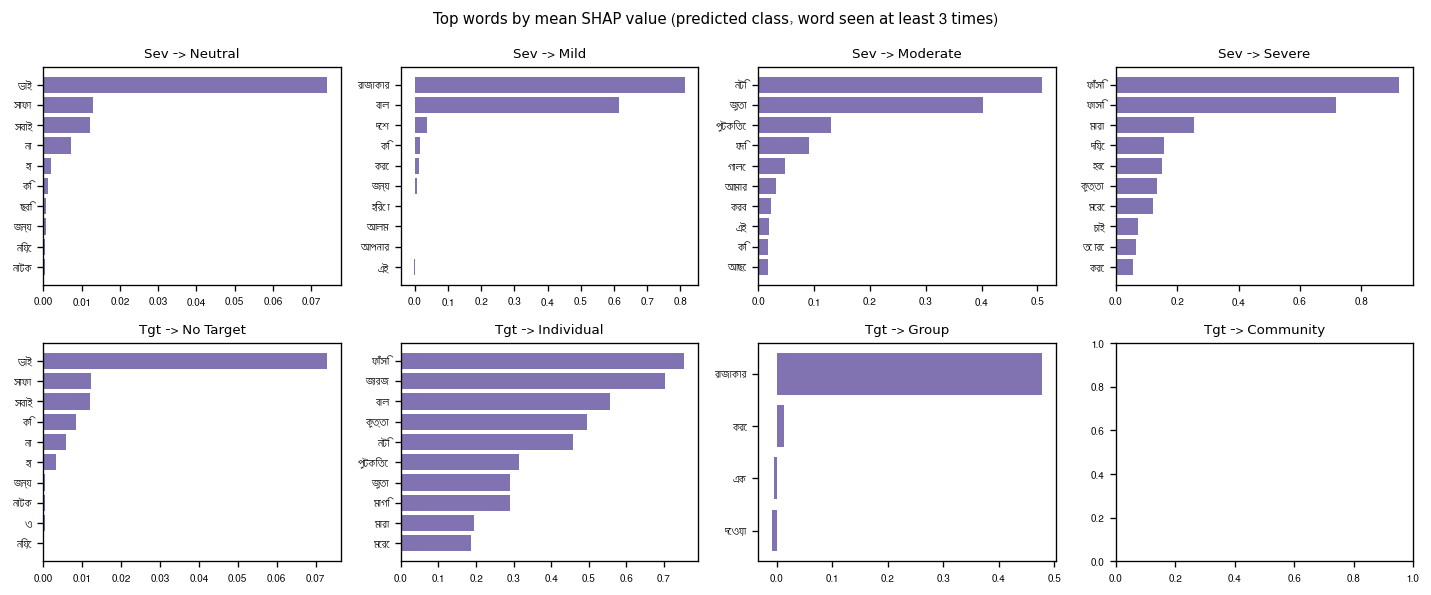

In [ ]:
def show_local(e, k=8):
    names = SEV_NAMES if e['task'] == 'sev' else TGT_NAMES
    print(f"[{'Severity' if e['task']=='sev' else 'Target'}] true={names[e['true']]} pred={names[e['pred']]} :: {e['text'][:160]}")
    for m in ['lime', 'shap']:
        if e[m] is None: continue
        order = np.argsort(-np.abs(e[m]))[:k]
        print(f'   {m.upper():4s}:', ', '.join(f"{e['words'][j]}({e[m][j]:+.3f})" for j in order))
for task in ['sev', 'tgt']:
    for correct in [True, False]:
        ex = [e for e in EXPL if e['task'] == task and (e['true'] == e['pred']) == correct]
        if ex: show_local(ex[0])

for task in ['sev', 'tgt']:
    sv = shap_expl[task]([XAI.text.iloc[0]], max_evals=300, silent=True)
    shap.plots.text(sv[0, :, int(XAI.ps.iloc[0] if task == 'sev' else XAI.pt.iloc[0])])

from collections import defaultdict
def shap_agg(task, c):
    agg = defaultdict(list)
    for e in EXPL:
        if e['task'] == task and e['pred'] == c and e['shap'] is not None:
            for w, v in zip(e['words'], e['shap']): agg[w].append(v)
    return agg

fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for row, (task, names) in enumerate([('sev', SEV_NAMES), ('tgt', TGT_NAMES)]):
    for c in range(4):
        agg = shap_agg(task, c)
        top = sorted(((np.mean(v), w) for w, v in agg.items() if len(v) >= SHAP_MIN_COUNT), reverse=True)[:10]
        ax = axes[row, c]
        if top:
            ax.barh([w for _, w in top][::-1], [v for v, _ in top][::-1], color='#8172B2')
        ax.set_title(f"{'Sev' if task=='sev' else 'Tgt'} -> {names[c]}", fontsize=8); ax.tick_params(labelsize=6)
fig.suptitle(f'Top words by mean SHAP value (predicted class, word seen at least {SHAP_MIN_COUNT} times)', fontsize=9)
savefig(fig, 'fig_shap_class_words')

rows = []
for task, names in [('sev', SEV_NAMES), ('tgt', TGT_NAMES)]:
    for c in range(4):
        agg = shap_agg(task, c)
        top = sorted(((np.mean(v), w) for w, v in agg.items() if len(v) >= SHAP_MIN_COUNT), reverse=True)[:10]
        for rank, (v, w) in enumerate(top, 1):
            rows.append({'Task': 'Severity' if task == 'sev' else 'Target', 'Predicted class': names[c],
                         'Rank': rank, 'Word': w, 'Mean SHAP': round(float(v), 4), 'n occurrences': len(agg[w])})
pd.DataFrame(rows).to_csv(os.path.join(RES, 'table_shap_top_words.csv'), index=False, encoding='utf-8-sig')

### 11.1 Faithfulness and stability
Comprehensiveness: drop in the predicted probability when the top-k% words are removed (higher is better).
Sufficiency: drop when only the top-k% words are kept (lower is better). Both are compared with a random-word
baseline. Stability: Jaccard overlap of the top-5 words across LIME seeds and after a meaning-preserving
perturbation.

In [ ]:
K_FRACS = [0.1, 0.2, 0.3]
def prob_of(task, texts, label): return predict_fn[task](texts)[:, label]
def topk_idx(w, frac):
    k = max(1, int(round(frac * len(w)))); return set(np.argsort(-w)[:k])

faith = []
for e in EXPL:
    words, lab, task = e['words'], e['pred'], e['task']
    base = prob_of(task, [e['text']], lab)[0]
    for method in ['lime', 'shap', 'random']:
        w = e[method] if method != 'random' else rng.rand(len(words))
        if w is None: continue
        for f in K_FRACS:
            top = topk_idx(w, f)
            removed = ' '.join(x for j, x in enumerate(words) if j not in top)
            kept = ' '.join(x for j, x in enumerate(words) if j in top)
            p_rm, p_keep = prob_of(task, [removed, kept], lab)
            faith.append({'task': task, 'method': method, 'k': f,
                          'comprehensiveness': base - p_rm, 'sufficiency': base - p_keep})
faith = pd.DataFrame(faith)
FT = faith.groupby(['task', 'method']).mean(numeric_only=True).drop(columns='k').round(4)
display(FT); FT.to_csv(os.path.join(RES, 'table_xai_faithfulness.csv'))

def jacc(a, b): return len(a & b) / max(1, len(a | b))
stab = []
for e in EXPL[:min(len(EXPL), 30)]:
    words, lab, task = e['words'], e['pred'], e['task']
    tops = [set(np.argsort(-lime_weights(e['text'], task, lab, seed=s))[:5]) for s in [1, 2, 3]]
    stab.append({'task': task, 'method': 'lime', 'check': 'seed',
                 'jaccard@5': np.mean([jacc(tops[0], tops[1]), jacc(tops[0], tops[2]), jacc(tops[1], tops[2])])})
    pert = e['text'] + ' ।'
    lw2 = lime_weights(pert, task, lab)[:len(words)]
    stab.append({'task': task, 'method': 'lime', 'check': 'perturb',
                 'jaccard@5': jacc(set(np.argsort(-e['lime'])[:5]), set(np.argsort(-lw2)[:5]))})
    if e['shap'] is not None:
        sw2, t2 = shap_weights(pert, task, lab)
        if len(t2) >= len(words):
            stab.append({'task': task, 'method': 'shap', 'check': 'perturb',
                         'jaccard@5': jacc(set(np.argsort(-e['shap'])[:5]), set(np.argsort(-sw2[:len(words)])[:5]))})
stab = pd.DataFrame(stab)
ST_T = stab.groupby(['task', 'method', 'check'])['jaccard@5'].agg(['mean', 'std', 'count']).round(4)
display(ST_T); ST_T.to_csv(os.path.join(RES, 'table_xai_stability.csv'))

comprehensiveness  sufficiency
task method                                
sev  lime               0.5835       0.1557
     random             0.1815       0.5102
     shap               0.5863       0.1346
tgt  lime               0.4767       0.1172
     random             0.0919       0.4707
     shap               0.4928       0.0949

mean     std  count
task method check                         
sev  lime   perturb  0.7849  0.2627     15
            seed     0.8156  0.2582     15
     shap   perturb  0.8952  0.1881     15
tgt  lime   perturb  0.8071  0.2661     15
            seed     0.8249  0.2457     15
     shap   perturb  0.8635  0.2407     15

## 12. Final Summary

In [ ]:
summary = {
    'n_train': len(tr), 'n_val': len(va), 'n_test': len(te), 'split_id': SPLIT_TAG,
    'seed': SEED, 'epochs': EPOCHS, 'max_len': MAX_LEN, 'batch_size': BATCH_SIZE,
    'versions': VERSIONS,
    'best_by_validation': BEST,
    'test_best': {t: R[(R.System == BEST[t]) & (R.Task == ('Severity' if t == 'sev' else 'Target')) &
                       (R.Split == 'test')].iloc[0][['Accuracy', 'Macro-F1', 'Weighted-F1']].to_dict()
                  for t in BEST},
}
json.dump(summary, open(os.path.join(RES, 'summary.json'), 'w'), indent=2, default=float, ensure_ascii=False)
print(json.dumps(summary, indent=2, default=float, ensure_ascii=False))
print('\nFiles in', RES); print(sorted(os.listdir(RES)))


{
  "n_train": 4102,
  "n_val": 879,
  "n_test": 877,
  "split_id": "0721b362d1",
  "seed": 42,
  "epochs": 6,
  "max_len": 128,
  "batch_size": 16,
  "versions": {
    "torch": "2.14.1+cu130",
    "transformers": "5.22.1",
    "scikit-learn": "1.6.1",
    "shap": "0.54.1",
    "lime": "0.2.0.1",
    "numpy": "2.4.6",
    "pandas": "2.2.3"
  },
  "best_by_validation": {
    "sev": "ST-Ens WeightedVote",
    "tgt": "All-Ens SoftVote"
  },
  "test_best": {
    "sev": {
      "Accuracy": 0.8324,
      "Macro-F1": 0.751,
      "Weighted-F1": 0.8301
    },
    "tgt": {
      "Accuracy": 0.8369,
      "Macro-F1": 0.6434,
      "Weighted-F1": 0.8366
    }
  }
}

Files in /content/drive/MyDrive/bangla_cyberbullying_thesis/results_v5
['all_results.xlsx', 'errors_test.csv', 'fig_classwise_f1.pdf', 'fig_classwise_f1.png', 'fig_cm_sev_best.pdf', 'fig_cm_sev_best.png', 'fig_cm_tgt_best.pdf', 'fig_cm_tgt_best.png', 'fig_data_distribution.pdf', 'fig_data_distribution.png', 'fig_model_comparison.pdf',

## 13. Blind Annotation Sheets
300 randomly sampled comments for two independent annotators, used later to measure real human agreement
(Cohen / Fleiss Kappa).

In [ ]:
N_BLIND = 300
blind = df.sample(frac=1, random_state=7).head(N_BLIND)[['id', 'text']].reset_index(drop=True)
for c in ['Severity_H1', 'Target_H1', 'Reason_H1']: blind[c] = ''
blind.to_excel(os.path.join(RES, 'blind_annotation_sheet_H1.xlsx'), index=False)
blind.rename(columns=lambda c: c.replace('H1', 'H2')).to_excel(os.path.join(RES, 'blind_annotation_sheet_H2.xlsx'),
                                                               index=False)
print('Saved blind_annotation_sheet_H1.xlsx and blind_annotation_sheet_H2.xlsx')

Saved blind_annotation_sheet_H1.xlsx and blind_annotation_sheet_H2.xlsx
